In [1]:
import os
from pathlib import Path
print(f'Changing to {Path().resolve().parent}')
os.chdir(Path().resolve().parent)

Changing to /home/bnoordijk/vscode_projects/halcyon


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import networkx as nx
import numpy as np
from scipy.integrate import solve_ivp
from sympy import symbols, sympify
import torch
import re
import sys

# from halcyon.Models.MechanisticModel import ComplexODEModel, SBMLImportClassDummy
# from halcyon.RegulatoryNetwork import RegulatoryNetwork
import libsbml
# from sympy.parsing.sympy_parser import parse_expr

In [3]:
print(sys.version)
folder_path = "tests/6_gene_testv2/"
# folder_path = "tests/genenetweaver_outputs/"
sbml_path = folder_path + "test_scalefree.xml"
# sbml_path = "tests/models/pokhilko2012.xml"

3.10.16 | packaged by conda-forge | (main, Dec  5 2024, 14:16:10) [GCC 13.3.0]


In [4]:
# def test_import_from_sbml():
#     # sbml_path = "tests/genenetweaver_outputs/test_scalefree.xml"
#     # sbml_path = "tests/models/pokhilko2012.xml"
#     my_importclass_test = SBMLImportClassDummy.from_sbml(sbml_path)
#     return my_importclass_test

In [5]:
# imported = test_import_from_sbml()
# print(imported)

In [4]:
sbml_path

'tests/6_gene_testv2/test_scalefree.xml'

In [5]:
reader = libsbml.SBMLReader()
document = reader.readSBML(sbml_path)  # type: ignore
model = document.getModel()
print(model.getNumReactions())
# To get the parameters of the model, you can use getListOfParameters()
parameters = model.getListOfParameters()
print(f"Number of parameters in the model: {parameters.size()}")
for i in range(parameters.size()):
    param = parameters.get(i)
    print(f"Parameter id: {param.getId()}, value: {param.getValue()}")

12
Number of parameters in the model: 0


In [8]:
parameters

<ListOfParameters[0]>

[('tellurium', '2.2.11.1'), ('roadrunner', '2.8.0'), ('antimony', '3.0.0'), ('libsbml', '5.20.5'), ('libsedml', '2.0.33'), ('phrasedml', '1.3.0')]
Node_0 initial value: 0.0
Node_1 initial value: 0.0
Node_2 initial value: 0.0
Node_3 initial value: 0.0
Node_4 initial value: 0.0
Node_5 initial value: 0.0
-----
Node_0 initial value: 0.1780818
Node_1 initial value: 0.9222381
Node_2 initial value: 0.1129278
Node_3 initial value: 1.0
Node_4 initial value: 0.1310036
Node_5 initial value: 0.8210416
['Node_0', 'Node_1', 'Node_2', 'Node_3', 'Node_4', 'Node_5']


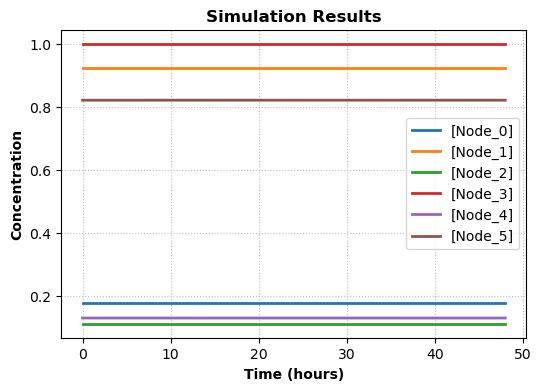

In [56]:
#install tellurium: https://tellurium.readthedocs.io/en/latest/installation.html
import tellurium as te

print(te.getVersionInfo())

# Load the SBML model from a file
# sbml_file = sys.argv[1]
model = te.loadSBMLModel(sbml_path)

# model.selections = ['cCOP1c', 'cCOP1d', 'cCOP1n', 'cE3', 'cE3_m', 'cE3n', 'cE4', 'cE4_m', 'cEC', 'cEG', 'cG', 'cG_m', 'cL', 'cLUX', 'cLUX_m', 'cL_m', 'cLm', 'cNI', 'cNI_m', 'cP', 'cP7', 'cP7_m', 'cP9', 'cP9_m', 'cT', 'cT_m', 'cZG', 'cZTL']
# model.selections = ['cP', 'cP7', 'cP7_m', 's1', 's15', 's37']

# Reset model to its initial state (species initialized as per model)
# model.reset()

# Print initial concentrations of all species
species = model.getFloatingSpeciesIds()
for s in species:
    print(f"{s} initial value: {model[s]}")
# print(species)
print('-----')
# Load initial values from TSV file
init_df = pd.read_csv(folder_path + "test_scalefree_nonoise_wildtype.tsv", sep="\t")
# Assume columns are node_names and values are in the first row
y0 = init_df.loc[0, species].values.astype(float)

for i, sp in enumerate(species):
    model[sp] = y0[i]
    
# Print initial concentrations of all species
species = model.getFloatingSpeciesIds()
for s in species:
    print(f"{s} initial value: {model[s]}")
print(species)

#This script will import an SBML model (eg from GeneNetWeaver) and simulate it.

# Simulate the model
result = model.simulate(0, 48, 50)  

# Plot the results

# Plot with axis labels
model.plot(result, xlabel='Time (hours)', ylabel='Concentration', title='Simulation Results', grid=True)


In [38]:
result

        time,  [Node_0],  [Node_1],  [Node_2],  [Node_3],    [Node_4],  [Node_5]
 [[        0,         0,         0,         0,         0,           0,         0],
  [ 0.979592, 0.0281242, 0.0398251, 0.0246195, 0.0403485, 0.000854956,  0.021094],
  [  1.95918, 0.0548445, 0.0780641, 0.0486327, 0.0790689,  0.00193319, 0.0410631],
  [  2.93878, 0.0802553,   0.11478, 0.0720518,  0.116227,  0.00338495, 0.0600007],
  [  3.91837,  0.104477,  0.150033, 0.0948728,  0.151886,  0.00531104, 0.0779898],
  [  4.89796,  0.127661,  0.183878,  0.117041,  0.186106,  0.00777437, 0.0951022],
  [  5.87755,  0.149984,  0.216367,  0.138393,  0.218945,    0.010805,    0.1114],
  [  6.85714,  0.171628,  0.247544,  0.158586,   0.25046,   0.0144019,  0.126936],
  [  7.83673,  0.192741,  0.277447,  0.177072,  0.280703,   0.0185316,  0.141756],
  [  8.81633,  0.213396,   0.30611,  0.193194,  0.309725,   0.0231285,    0.1559],
  [  9.79592,  0.233564,  0.333558,  0.206408,  0.337577,   0.0281005,  0.169404],
  [  1

In [23]:
a = te.getODEsFromSBMLFile(sbml_path)

In [24]:
print(a)


vNode_0_synthesis = cell*max*(a_0*(1-pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1)))*(1-pow(Node_2/k_2,n_2)/(1+pow(Node_2/k_2,n_2)))+a_1*(pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1)))*(1-pow(Node_2/k_2,n_2)/(1+pow(Node_2/k_2,n_2)))+a_2*(1-pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1)))*(pow(Node_2/k_2,n_2)/(1+pow(Node_2/k_2,n_2)))+a_3*(pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1)))*(pow(Node_2/k_2,n_2)/(1+pow(Node_2/k_2,n_2))))
vNode_0_degradation = cell*delta*Node_0
vNode_1_synthesis = cell*max*(a_0*(1-pow(Node_2/k_1,n_1)*pow(Node_0/k_2,n_2)*pow(Node_3/k_3,n_3)/(1+pow(Node_2/k_1,n_1))*(1+pow(Node_0/k_2,n_2))*(1+pow(Node_3/k_3,n_3)))+a_1*(pow(Node_2/k_1,n_1)*pow(Node_0/k_2,n_2)*pow(Node_3/k_3,n_3)/(1+pow(Node_2/k_1,n_1))*(1+pow(Node_0/k_2,n_2))*(1+pow(Node_3/k_3,n_3))))
vNode_1_degradation = cell*delta*Node_1
vNode_2_synthesis = cell*max*(a_0*(1-pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1)))+a_1*(pow(Node_1/k_1,n_1)/(1+pow(Node_1/k_1,n_1))))
vNode_2_degradation = cell*delta*Node_2
vNode_3_synthe

In [54]:
result[:,1:]

 [[         0,         0,         0,         0,           0,         0],
  [ 0.0281242, 0.0398251, 0.0246195, 0.0403485, 0.000854956,  0.021094],
  [ 0.0548445, 0.0780641, 0.0486327, 0.0790689,  0.00193319, 0.0410631],
  [ 0.0802553,   0.11478, 0.0720518,  0.116227,  0.00338495, 0.0600007],
  [  0.104477,  0.150033, 0.0948728,  0.151886,  0.00531104, 0.0779898],
  [  0.127661,  0.183878,  0.117041,  0.186106,  0.00777437, 0.0951022],
  [  0.149984,  0.216367,  0.138393,  0.218945,    0.010805,    0.1114],
  [  0.171628,  0.247544,  0.158586,   0.25046,   0.0144019,  0.126936],
  [  0.192741,  0.277447,  0.177072,  0.280703,   0.0185316,  0.141756],
  [  0.213396,   0.30611,  0.193194,  0.309725,   0.0231285,    0.1559],
  [  0.233564,  0.333558,  0.206408,  0.337577,   0.0281005,  0.169404],
  [  0.253121,  0.359816,  0.216513,  0.364304,   0.0333414,  0.182305],
  [  0.271898,  0.384906,  0.223704,  0.389954,   0.0387468,  0.194638],
  [  0.289727,  0.408852,  0.228438,  0.414568,   0

In [46]:
result

        time,  [Node_0],  [Node_1],  [Node_2],  [Node_3],    [Node_4],  [Node_5]
 [[        0,         0,         0,         0,         0,           0,         0],
  [ 0.979592, 0.0281242, 0.0398251, 0.0246195, 0.0403485, 0.000854956,  0.021094],
  [  1.95918, 0.0548445, 0.0780641, 0.0486327, 0.0790689,  0.00193319, 0.0410631],
  [  2.93878, 0.0802553,   0.11478, 0.0720518,  0.116227,  0.00338495, 0.0600007],
  [  3.91837,  0.104477,  0.150033, 0.0948728,  0.151886,  0.00531104, 0.0779898],
  [  4.89796,  0.127661,  0.183878,  0.117041,  0.186106,  0.00777437, 0.0951022],
  [  5.87755,  0.149984,  0.216367,  0.138393,  0.218945,    0.010805,    0.1114],
  [  6.85714,  0.171628,  0.247544,  0.158586,   0.25046,   0.0144019,  0.126936],
  [  7.83673,  0.192741,  0.277447,  0.177072,  0.280703,   0.0185316,  0.141756],
  [  8.81633,  0.213396,   0.30611,  0.193194,  0.309725,   0.0231285,    0.1559],
  [  9.79592,  0.233564,  0.333558,  0.206408,  0.337577,   0.0281005,  0.169404],
  [  1